# Glacier-supported Population Processing & Analysis
The following notebook includes the code that is used to perform analyses to derive the number of people supported by glacier-sourced water. Some figures for the manuscript are included here, while the processed datasets are also used in other jupyter notebooks as well.

Overall, these analyses support a PyGEM-WBM glacier use study.

In [1]:
import os

from tqdm import tqdm

from affine import Affine
import cartopy
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib as mpl
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import ListedColormap
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
import matplotlib.path as mpath
import matplotlib.patches as patches
from matplotlib.patches import Patch
from matplotlib.patches import FancyArrowPatch
from matplotlib.patches import Polygon
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import AutoMinorLocator, MultipleLocator, FixedLocator, LogLocator, NullFormatter
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import pandas as pd
from rasterstats import zonal_stats
import rioxarray
import rasterio
from rasterio.features import rasterize
from scipy.ndimage import uniform_filter
from scipy.spatial import ConvexHull
from scipy.spatial import cKDTree
from shapely.geometry import Point
import xarray as xr

In [2]:
main_directory = os.getcwd()

ssps = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
gcm_names = ['BCC-CSM2-MR', 'CESM2', 'CESM2-WACCM', 'EC-Earth3', 'EC-Earth3-Veg', 'FGOALS-f3-L', 
             'GFDL-ESM4', 'INM-CM4-8', 'INM-CM5-0', 'MPI-ESM1-2-HR', 'MRI-ESM2-0', 'NorESM2-MM']

# RGI data
rgi_reg_fp = 'rgi_regions/'
rgi_reg_fn = '00_rgi60_O1Regions.shp'

# Plotting details
ssp_name_dict = {'126':'SSP1-2.6',
                 '245':'SSP2-4.5',
                 '370':'SSP3-7.0',
                 '585':'SSP5-8.5',
                 'ssp126':'SSP1-2.6',
                 'ssp245':'SSP2-4.5',
                 'ssp370':'SSP3-7.0',
                 'ssp585':'SSP5-8.5',
                }
ssp_colordict = {'119':'#081d58', '126':'#1d91c0', '245':'#7fcdbb', '370':'#F47A20', '585':'#ED2024',
                'ssp119':'#081d58', 'ssp126':'#1d91c0', 'ssp245':'#7fcdbb', 'ssp370':'#F47A20', 'ssp585':'#ED2024'}
# ssp_colordict = {'126':'#2D446B', '245':'#DE944B', '370':'#CD4644', '585':'#7E2825'} # IPCC AR6 colors
# ssp_colordict = {'126':'#DE944B', '245':'#D25B4E', '370':'#9F2C2A', '585':'#7E2825'} # Yellow-Red

paper_fig_fp = 'figures_paper/'
if not os.path.exists(paper_fig_fp):
    os.makedirs(paper_fig_fp)

min_frac = 0.01

### Rasterized Continents 
Makes subsetting by continents easier & consistent with WBM products

In [3]:
cont_fp = 'ipcc_regions/'
cont_fn = 'IPCC-WGII-continental-regions.geojson'
rasterized_fn = "IPCC-WGII-continental-regions-id.nc"

cont_gdf = gpd.read_file(cont_fp + cont_fn)

if not os.path.exists(cont_fp + rasterized_fn):
    # --- Match CRS (lat/lon assumed WGS84) ---
    cont_gdf = cont_gdf.to_crs("EPSG:4326")
    
    # --- Grid from dataset ---
    lon = ds_irrProd['longitude'].values
    lat = ds_irrProd['latitude'].values  # descending
    
    # --- Resolution ---
    lon_res = lon[1] - lon[0]
    lat_res = lat[1] - lat[0]  # this will be negative
    
    # --- Build transform (note negative y scale) ---
    transform = (
        Affine.translation(lon.min() - lon_res / 2, lat.max() - abs(lat_res) / 2)
        * Affine.scale(lon_res, lat_res)
    )
    
    # --- Prepare shapes ---
    shapes = [
        (geom, value)
        for geom, value in zip(cont_gdf.geometry, cont_gdf['id'])
    ]
    
    # --- Rasterize ---
    raster = rasterize(
        shapes=shapes,
        out_shape=(len(lat), len(lon)),
        transform=transform,
        fill=0,
        dtype='float32'
    )
    
    # --- Create a standalone dataset ---
    ds_conts = xr.Dataset(
        data_vars={
            "cont_id": (("latitude", "longitude"), raster)
        },
        coords={
            "latitude": lat,
            "longitude": lon
        }
    )
    
    # --- Optional: add metadata ---
    ds_conts["cont_id"].attrs["long_name"] = "IPCC continental region ID"
    ds_conts["cont_id"].attrs["description"] = "Rasterized continental IDs from IPCC WGII shapefile"
    
    ds_conts.attrs["source"] = "IPCC-WGII-continental-regions.geojson"
    ds_conts.attrs["crs"] = "EPSG:4326"
    
    # --- Save to NetCDF ---
    ds_conts.to_netcdf(cont_fp + rasterized_fn)
else:
    ds_conts = xr.open_dataset(cont_fp + rasterized_fn)

cont_name2id = dict(zip(cont_gdf["Name"], cont_gdf["id"]))

In [4]:
cont_gdf

,Name,id,Acronym,area,area_land,area_sea,area_mountain,geometry
0,Antarctica,0,ANT,1.233777e+07,1.225232e+07,8.543717e+04,0.000000e+00,"MULTIPOLYGON (((-163.71300 -78.59600, -163.067..."
1,Europe,1,EUR,1.301014e+07,1.264882e+07,3.613626e+05,1.973741e+05,"MULTIPOLYGON (((32.25700 35.10300, 32.49000 34..."
2,Small Islands,2,SMA,9.454662e+05,7.249341e+05,2.205406e+05,0.000000e+00,"MULTIPOLYGON (((-61.20000 -51.85000, -60.70000..."
3,Africa,3,AFR,2.935579e+07,2.887079e+07,4.850495e+05,1.430758e+06,"POLYGON ((34.82300 29.76100, 34.26500 31.21900..."
4,Central and South America,4,CEN,1.835565e+07,1.795328e+07,4.024337e+05,0.000000e+00,"MULTIPOLYGON (((-74.66300 -52.83700, -73.28500..."
5,Australasia,5,AUS,7.964999e+06,7.720186e+06,2.448154e+05,0.000000e+00,"MULTIPOLYGON (((113.33900 -26.11700, 113.47700..."
6,Asia,6,ASI,4.389349e+07,4.287537e+07,1.017953e+06,1.296416e+06,"MULTIPOLYGON (((154.51400 -5.13900, 154.72900 ..."
7,North America,7,NOR,2.149530e+07,2.082931e+07,6.660531e+05,0.000000e+00,"MULTIPOLYGON (((-64.39300 46.72700, -64.14300 ..."


## Elevation data

In [5]:
dem_nc_fn = 'DEM/dem.nc'

if not os.path.exists(dem_nc_fn):
    dem_fn = 'DEM/15min_flwdir_seg_endrh_v2.elvAverg.tif'
    with rasterio.open(dem_fn) as src:
        data = src.read()[0,:,:]
        # Get the affine transformation and dimensions
        transform = src.transform
        height = src.height
        width = src.width
        
        # Create coordinate arrays
        y_coords = np.arange(height) * transform[4] + transform[5] - 0.125  # subtract 0.125 to be consistent with model setup
        x_coords = np.arange(width) * transform[0] + transform[2] + 0.125   # add 0.125 to be consistent with model setup
        bands = np.arange(data.shape[0])  # Band indices
        
        # # Create xarray DataArray
        # da = xr.DataArray(data, dims=('band', 'latitude', 'longitude'), 
        #                         coords={'band': bands,
        #                                 'latitude': y_coords,
        #                                 'longitude': x_coords})
        # Create xarray DataArray
        da = xr.DataArray(data, dims=('latitude', 'longitude'), 
                                coords={'latitude': y_coords,
                                        'longitude': x_coords})
        
    # Convert DataArray to Dataset if needed
    ds_elev = da.to_dataset(name='elev')
    elev_values = ds_elev.elev.values
    elev_values[elev_values<0] = np.nan
    ds_elev['elev'].values = elev_values
    
    ds_elev.to_netcdf(dem_nc_fn)

else:
    ds_elev = xr.open_dataset(dem_nc_fn)

# Populations - Time Series - by glacier fraction and elevation
Below describes several processing decisions that were made.

- The population data are provided at a higher resolution than the other datasets.  The other datasets (elevation and glacier fraction) are thus resampled (nearest neighbor) onto the population data before aggregations. Note that this does cause slight differences compared to resampling the population data to the coarser resolution.  Nearest neighbor was used given the coarse structure of the basins such that a pixel is either deemed in or outside the basin.
- Multi-GCM medians were calculated by aggregating to the unit of interest first before taking the median (e.g., each GCM/SSP for a given continent was calculated and then averaged after).

### Load population dataset and add elevation to be used for the analysis

In [6]:
# ----- POPULATION DATA -----
pop_fp = 'wbm_data/population_gridded/'
pop_fn = 'historical_population_per_grid.nc'

ds_pop = xr.open_dataset(pop_fp + pop_fn)
# Select subset that aligns with historical population data
ds_pop = ds_pop.isel(year=slice(0,16))
pop = ds_pop['population']
pop_2000_2015_mean = pop.mean(axis=0)

# ----- ADD ELEVATION DATA TO POPULATION -----
# Extract latitude, longitude, and elevation data
lat_orig = ds_elev['latitude'].values
lon_orig = ds_elev['longitude'].values
elevation_data = ds_elev['elev'].values

# Define the new grid's latitudes and longitudes
lat_new = ds_pop.latitude.values
lon_new = ds_pop.longitude.values

# Find nearest indices for latitudes and longitudes using broadcasting
nearest_lat_indices = np.abs(lat_orig[:, np.newaxis] - lat_new).argmin(axis=0)
nearest_lon_indices = np.abs(lon_orig[:, np.newaxis] - lon_new).argmin(axis=0)

# Use advanced indexing to get the nearest elevation values
nearest_elevation = elevation_data[nearest_lat_indices[:, np.newaxis], nearest_lon_indices]

ds_pop['elev'] = (("latitude", "longitude"), nearest_elevation)

# Elevation
elev_df = (
    ds_pop['elev']
    .to_dataframe()
    .reset_index()
)
elev_df.head()

,latitude,longitude,elev
0,89.95,-179.95,NaN
1,89.95,-179.85,NaN
2,89.95,-179.75,NaN
3,89.95,-179.65,NaN
4,89.95,-179.55,NaN


### Processing function to convert how data are processed/stored into a dataframe

In [7]:
def process_continent_sums(cont_sums_df):
    """
    Convert continent summary dataframe with columns of the form
    'YYYY-frac-elevXXX' into a dataframe with columns:

        Name | elev_threshold | frac | 1980 | 1981 | ...

    Adds a Global row, removes Africa, and places Global first.
    """
    # Add global
    global_sums_df = cont_sums_df.sum(axis=0).to_frame().T
    global_sums_df.index = ['Global']

    cont_sums_df = pd.concat([global_sums_df, cont_sums_df])
    cont_sums_df = cont_sums_df.reset_index(names='Name')

    # Process data into region, frac, elev
    yr_frac_elev_cns = [c for c in cont_sums_df.columns if c != 'Name']

    tmp = cont_sums_df.melt(id_vars=['Name'], value_vars=yr_frac_elev_cns, var_name='year_frac_elev', value_name='value')

    # Split into year, frac, elev
    tmp[['year', 'frac', 'elev_threshold']] = tmp['year_frac_elev'].str.extract(r'(\d+)-([\d\.]+)-elev(\d+)')
    tmp['year'] = tmp['year'].astype(int)
    tmp['frac'] = tmp['frac'].astype(float)
    tmp['elev_threshold'] = tmp['elev_threshold'].astype(int)

    # Pivot so years become columns
    out = tmp.pivot_table(index=['Name', 'elev_threshold', 'frac'], columns='year', values='value').reset_index()
    out.columns.name = None

    # Remove Africa & place Global at top
    out = out[out['Name'] != 'Africa']

    out = pd.concat([out[out['Name'] == 'Global'], out[out['Name'] != 'Global']], ignore_index=True)

    return out

## Historical

In [8]:
elev_thresholds = [0, 2500, 3000, 4000]
min_fracs = [0.01, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]

In [9]:
# Domestic people files
dom_people_pg_fp = 'processed_data/domestic_pg_people/'
dom_people_pg_fn = 'historical_global_continents_people_pg_ERA5-byfrac-byelev.csv'

# Domestic fraction files
dom_pg_frac_fp = 'wbm_data/domestic_pg_frac/'
dom_pg_frac_fn = 'historical_dom_pg.shp'


# ----- Load Fraction Data ----
dom_pg_frac_gdf_raw = gpd.read_file(dom_pg_frac_fp + dom_pg_frac_fn)
dom_pg_frac_gdf_raw['2006-2015'] = dom_pg_frac_gdf_raw.loc[:,[str(x) for x in range(2006,2016)]].mean(axis=1)

# ----- Add continents -----
dom = dom_pg_frac_gdf_raw.copy()
cont = cont_gdf.copy()

# Project to equal-area / metric CRS (critical for area calc)
dom = dom.to_crs(epsg=6933)
cont = cont.to_crs(epsg=6933)

# Add unique ID to domestic polygons
dom["dom_id"] = np.arange(len(dom))

# Compute polygon intersections (all overlaps) ---
intersections = gpd.overlay(dom, cont, how='intersection')

# Compute overlap area
intersections["overlap_area"] = intersections.geometry.area

# Keep only real overlaps
intersections = intersections[intersections['overlap_area'] > 0]

# For each dom polygon, keep continent with max overlap
best_match = intersections.sort_values("overlap_area", ascending=False).drop_duplicates(subset="dom_id", keep="first")

# Join result back to original dom dataframe
dom_pg_frac_gdf = dom.merge(best_match[["dom_id", "Name"]], on="dom_id", how="left")

# Convert back to lat/lon CRS
dom_pg_frac_gdf = dom_pg_frac_gdf.to_crs(epsg=4326)

# ----- PROCESS/AGGREGATE DATA -----
if not os.path.exists(dom_people_pg_fp + dom_people_pg_fn):

    for nyear, year in enumerate(np.arange(1980,2016)):

        yr_str = str(year)

        if nyear%10 == 0:
            print('  ', year)

        # Convert to dataframe
        if year < 2000:
            pop_df = pop[0,:,:].to_dataframe().reset_index()
        else:
            yr_idx = np.where(ds_pop.year == year)[0][0]
            pop_df = pop[yr_idx,:,:].to_dataframe().reset_index()

        # Add elevation
        pop_df = pop_df.merge(elev_df, on=['latitude', 'longitude'])

        # Convert to geodataframe
        pop_gdf = gpd.GeoDataFrame(pop_df, geometry=gpd.points_from_xy(pop_df.longitude, pop_df.latitude), crs="EPSG:4326")

        # Spatial join
        # - 'inner' tells it to use keys (column names) from both dataframes and retain those on the left
        # - 'within' tells to join any where the point is within the vector data
        pop_gdf_wbasin = gpd.sjoin(pop_gdf, dom_pg_frac_gdf, how="inner", predicate="within")

        # Force one basin per point (just as a check; this should not occur)
        pop_gdf_wbasin = pop_gdf_wbasin.sort_index().drop_duplicates(subset=["latitude", "longitude"], keep="first")


        # Calculate glacier-supported people people
        # Convert fraction of domestic to people supported by multiplying by population for given year
        # - note don't process all years at once because the population data is changing each year too
        cont_sums = {}
        dom_frac_yr = np.copy(pop_gdf_wbasin[yr_str])
        dom_frac_yr[np.isnan(dom_frac_yr)] = 0
        
        for min_frac in min_fracs:
            dom_frac_mask = np.ones(dom_frac_yr.shape)
            dom_frac_mask[dom_frac_yr < min_frac] = 0

            # print(year, min_frac, dom_frac_yr[dom_frac_yr>min_frac].min(), dom_frac_yr.max())

            for elev_threshold in elev_thresholds:
                elev_mask = np.ones(pop_gdf_wbasin.shape[0])
                elev_mask[pop_gdf_wbasin['elev'] < elev_threshold] = 0
    
                pop_gdf_wbasin[yr_str] = pop_gdf_wbasin['population'] * dom_frac_yr * dom_frac_mask * elev_mask
                
                # Aggregate using groupby
                dom_people_pg_conts_sum = pop_gdf_wbasin.groupby('Name')[yr_str].sum()
    
                cont_sums[yr_str + '-' + str(min_frac) + '-elev' + str(elev_threshold)] = dom_people_pg_conts_sum
        cont_sums_df = pd.DataFrame(cont_sums)

        cont_sums_df_processed = process_continent_sums(cont_sums_df)

        # Add Stats to region geodataframe
        if nyear==0:
            conts_dom_people_pg_df = cont_sums_df_processed
            conts_dom_people_pg_df = conts_dom_people_pg_df.rename(columns={year: yr_str})
        else:
            conts_dom_people_pg_df[yr_str] = cont_sums_df_processed[year]

    # Export global file
    if not os.path.exists(dom_people_pg_fp):
        os.makedirs(dom_people_pg_fp)
    conts_dom_people_pg_df.to_csv(dom_people_pg_fp + dom_people_pg_fn, index=False)

In [10]:
# conts_dom_people_pg_df.head()

### People in basins by fraction of glacier water at present (2006-2015)

In [11]:
dom_people_tot_fn = 'historical_global_continents_people_tot_ERA5-byfrac-byelev.csv'

if not os.path.exists(dom_people_pg_fp + dom_people_tot_fn):

    for nyear, year in enumerate(np.arange(1980,2016)):

        if nyear%10 == 0:
            print('  ', year)

        # Convert to dataframe
        if year < 2000:
            pop_df = pop[0,:,:].to_dataframe().reset_index()
        else:
            yr_idx = np.where(ds_pop.year == year)[0][0]
            pop_df = pop[yr_idx,:,:].to_dataframe().reset_index()

        # Add elevation
        pop_df = pop_df.merge(elev_df, on=['latitude', 'longitude'])

        # Convert to geodataframe
        pop_gdf = gpd.GeoDataFrame(pop_df, geometry=gpd.points_from_xy(pop_df.longitude, pop_df.latitude), crs="EPSG:4326")

        # Spatial join
        # - 'inner' tells it to use keys (column names) from both dataframes and retain those on the left
        # - 'within' tells to join any where the point is within the vector data
        pop_gdf_wbasin = gpd.sjoin(pop_gdf, dom_pg_frac_gdf, how="inner", predicate="within")

        # Force one basin per point (just as a check; this should not occur)
        pop_gdf_wbasin = pop_gdf_wbasin.sort_index().drop_duplicates(subset=["latitude", "longitude"], keep="first")

        # Calculate total people
        # Convert fraction of domestic to people supported by multiplying by population for given year
        # - note don't process all years at once because the population data is changing each year too
        cont_sums = {}
        dom_frac_yr = np.copy(pop_gdf_wbasin['2006-2015'])  # the year column is the domestic fraction
        dom_frac_yr[np.isnan(dom_frac_yr)] = 0
        for min_frac in min_fracs:

            dom_frac_mask = np.ones(dom_frac_yr.shape)
            dom_frac_mask[dom_frac_yr < min_frac] = 0

            for elev_threshold in elev_thresholds:
                elev_mask = np.ones(pop_gdf_wbasin.shape[0])
                elev_mask[pop_gdf_wbasin['elev'] < elev_threshold] = 0
    
                pop_gdf_wbasin[year] = pop_gdf_wbasin['population'] * dom_frac_mask * elev_mask

                # # Global check                
                # print(np.round(np.nansum(pop_gdf_wbasin['population'][dom_frac_yr>=min_frac] * dom_frac_yr[dom_frac_yr>=min_frac])/1e6,3), 
                #       'million glacier-supported people')
                # print(np.round(np.nansum(pop_gdf_wbasin['population'] * dom_frac_mask * elev_mask * dom_frac_yr)/1e6,3), 
                #       'million glacier-supported people')
    
                # print('\n')
                # print(np.round(np.nansum(pop_gdf_wbasin['population'][dom_frac_yr>=min_frac])/1e6,3), 
                #       'million total people')
                # print(np.round(np.nansum(pop_gdf_wbasin['population'] * dom_frac_mask * elev_mask)/1e6,3), 
                #       'million total people')
                
                # Aggregate using groupby
                dom_people_pg_conts_sum = pop_gdf_wbasin.groupby('Name')[year].sum()
    
                cont_sums[str(year) + '-' + str(min_frac) + '-elev' + str(elev_threshold)] = dom_people_pg_conts_sum

        cont_sums_df = pd.DataFrame(cont_sums)

        cont_sums_df_processed = process_continent_sums(cont_sums_df)

        # Add Stats to region geodataframe
        if nyear==0:
            conts_dom_people_pg_df = cont_sums_df_processed
            conts_dom_people_pg_df = conts_dom_people_pg_df.rename(columns={year: str(year)})
        else:
            conts_dom_people_pg_df[str(year)] = cont_sums_df_processed[year]

    # Export global file
    if not os.path.exists(dom_people_pg_fp):
        os.makedirs(dom_people_pg_fp)
    conts_dom_people_pg_df.to_csv(dom_people_pg_fp + dom_people_tot_fn, index=False)

In [12]:
# conts_dom_people_pg_df.loc[(conts_dom_people_pg_df['Name']=='Global') & (conts_dom_people_pg_df['elev_threshold']==0)]

#### Total people in basins values for manuscript

In [13]:
people_pg_df = pd.read_csv(dom_people_pg_fp + dom_people_pg_fn)
people_tot_df = pd.read_csv(dom_people_pg_fp + dom_people_tot_fn)

decade_cns = [str(x) for x in range(2006,2016)]

for frac in [0.01, 0.1, 0.2, 0.5]:
    
    # glacier-supported people
    tot_pg_2006_2015 = people_pg_df.loc[(people_pg_df['Name'] == 'Global') & 
                                        (people_pg_df['elev_threshold'] == 0) & 
                                        (people_pg_df['frac'] == frac), decade_cns].values[0,:].mean()

    # total people
    tot_pop_2006_2015 = people_tot_df.loc[(people_tot_df['Name'] == 'Global') & 
                                          (people_tot_df['elev_threshold'] == 0) & 
                                          (people_tot_df['frac'] == frac), decade_cns].values[0,:].mean()

    print('\n', str(int(frac*100)) + '%')
    print('  Total people:', np.round(np.mean(tot_pop_2006_2015)/1e6,3), 'million')
    print('  Glacier-supported people:', np.round(np.mean(tot_pg_2006_2015)/1e6,3), 'million')


 1%
  Total people: 732.26 million
  Glacier-supported people: 30.983 million

 10%
  Total people: 37.073 million
  Glacier-supported people: 6.443 million

 20%
  Total people: 2.871 million
  Glacier-supported people: 1.129 million

 50%
  Total people: 0.041 million
  Glacier-supported people: 0.035 million


#### Breakdown by elevation

In [14]:
people_pg_df = pd.read_csv(dom_people_pg_fp + dom_people_pg_fn)
people_tot_df = pd.read_csv(dom_people_pg_fp + dom_people_tot_fn)

decade_cns = [str(x) for x in range(2006,2016)]

for elev in [0, 2500, 3000, 4000]:
    
    # glacier-supported people
    tot_pg_2006_2015 = people_pg_df.loc[(people_pg_df['Name'] == 'Global') & 
                                        (people_pg_df['elev_threshold'] == elev) & 
                                        (people_pg_df['frac'] == 0.01), decade_cns].values[0,:].mean()

    # total people
    tot_pop_2006_2015 = people_tot_df.loc[(people_tot_df['Name'] == 'Global') & 
                                          (people_tot_df['elev_threshold'] == elev) & 
                                          (people_tot_df['frac'] == 0.01), decade_cns].values[0,:].mean()

    print('\n', elev, 'm')
    print('  Total people:', np.round(np.mean(tot_pop_2006_2015)/1e6,3), 'million')
    print('  Glacier-supported people:', np.round(np.mean(tot_pg_2006_2015)/1e6,3), 'million')
    print('  Percent:', np.round(100 * tot_pg_2006_2015 / tot_pop_2006_2015,2))


 0 m
  Total people: 732.26 million
  Glacier-supported people: 30.983 million
  Percent: 4.23

 2500 m
  Total people: 18.399 million
  Glacier-supported people: 0.916 million
  Percent: 4.98

 3000 m
  Total people: 12.593 million
  Glacier-supported people: 0.631 million
  Percent: 5.01

 4000 m
  Total people: 6.183 million
  Glacier-supported people: 0.286 million
  Percent: 4.62


#### Breakdown to regions

In [15]:
rois = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']

for roi in rois:

    # glacier-supported people
    tot_pg_2006_2015 = people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                                        (people_pg_df['elev_threshold'] == 0) & 
                                        (people_pg_df['frac'] == 0.01), decade_cns].values[0,:].mean()

    # total people
    tot_pop_2006_2015 = people_tot_df.loc[(people_tot_df['Name'] == roi) & 
                                          (people_tot_df['elev_threshold'] == 0) & 
                                          (people_tot_df['frac'] == 0.01), decade_cns].values[0,:].mean()

    print('\n', roi)
    print('  Total people:', np.round(np.mean(tot_pop_2006_2015)/1e6,3), 'million')
    print('  Glacier-supported people:', np.round(np.mean(tot_pg_2006_2015)/1e6,3), 'million')


 Global
  Total people: 732.26 million
  Glacier-supported people: 30.983 million

 Asia
  Total people: 606.588 million
  Glacier-supported people: 26.118 million

 Europe
  Total people: 87.778 million
  Glacier-supported people: 2.653 million

 North America
  Total people: 14.356 million
  Glacier-supported people: 0.941 million

 Central and South America
  Total people: 23.408 million
  Glacier-supported people: 1.263 million

 Australasia
  Total people: 0.13 million
  Glacier-supported people: 0.007 million


<br><br>
### Future people in basins with at least 0.01 glacier water at present

In [16]:
ssp_pop_dict = {'ssp126':'SSP1_RCP2_6',
                'ssp245':'SSP2_RCP4_5',
                'ssp370':'SSP3_RCP7',
                'ssp585':'SSP5_RCP8_5'}

for nssp, ssp in enumerate(ssps):

    dom_people_tot_fn = ssp + '_global_continents_people_tot-byfrac-byelev.csv'

    if not os.path.exists(dom_people_pg_fp + dom_people_tot_fn):

        print(ssp)

        # Population data
        pop_fn = ssp_pop_dict[ssp] + '_population_per_grid.nc'
        ds_pop = xr.open_dataset(pop_fp + pop_fn)
        # Select subset that aligns with GCMs
        ds_pop = ds_pop.isel(year=slice(16,100))
    
        pop = ds_pop['population']

        # Process to points and aggregate
        for nyear, year in enumerate(np.arange(2016,2100)):
            
            if nyear%10==0:
                print('  ', year)
            
            # Convert to dataframe
            yr_idx = np.where(ds_pop.year == year)[0][0]
            pop_df = pop[yr_idx,:,:].to_dataframe().reset_index()

            # Add elevation
            pop_df = pop_df.merge(elev_df, on=['latitude', 'longitude'])
    
            # Convert to geodataframe
            pop_gdf = gpd.GeoDataFrame(pop_df, geometry=gpd.points_from_xy(pop_df.longitude, pop_df.latitude), crs="EPSG:4326")

            # Spatial join
            # - 'inner' tells it to use keys (column names) from both dataframes and retain those on the left
            # - 'within' tells to join any where the point is within the vector data
            pop_gdf_wbasin = gpd.sjoin(pop_gdf, dom_pg_frac_gdf, how="inner", predicate="within")
    
            # Force one basin per point (just as a check; this should not occur)
            pop_gdf_wbasin = pop_gdf_wbasin.sort_index().drop_duplicates(subset=["latitude", "longitude"], keep="first")

            
            # Calculate total people
            # - note don't process all years at once because the population data is changing each year too
            cont_sums = {}
            dom_frac_yr = np.copy(pop_gdf_wbasin['2006-2015'])  # the year column is the domestic fraction
            dom_frac_yr[np.isnan(dom_frac_yr)] = 0
            for min_frac in min_fracs:
                dom_frac_mask = np.ones(dom_frac_yr.shape)
                dom_frac_mask[dom_frac_yr < min_frac] = 0
    
                for elev_threshold in elev_thresholds:
                    elev_mask = np.ones(pop_gdf_wbasin.shape[0])
                    elev_mask[pop_gdf_wbasin['elev'] < elev_threshold] = 0
        
                    pop_gdf_wbasin[year] = pop_gdf_wbasin['population'] * dom_frac_mask * elev_mask
                    
                    # Aggregate using groupby
                    dom_people_pg_conts_sum = pop_gdf_wbasin.groupby('Name')[year].sum()
        
                    cont_sums[str(year) + '-' + str(min_frac) + '-elev' + str(elev_threshold)] = dom_people_pg_conts_sum
    
            cont_sums_df = pd.DataFrame(cont_sums)
    
            cont_sums_df_processed = process_continent_sums(cont_sums_df)

            # Add Stats to region geodataframe
            if nyear==0:
                conts_dom_people_pg_df = cont_sums_df_processed
                conts_dom_people_pg_df = conts_dom_people_pg_df.rename(columns={year: str(year)})
            else:
                conts_dom_people_pg_df[str(year)] = cont_sums_df_processed[year]

        # Export global file
        if not os.path.exists(dom_people_pg_fp):
            os.makedirs(dom_people_pg_fp)
        conts_dom_people_pg_df.to_csv(dom_people_pg_fp + dom_people_tot_fn, index=False)

## Future glacier-supported people

In [17]:
dom_people_pg_fp_gcms = 'processed_data/domestic_pg_people/individual_gcms/'

for nssp, ssp in enumerate(ssps):
    
    for ngcm, gcm_name in enumerate(gcm_names):

        global_dom_people_pg_fn = gcm_name + '_' + ssp + '_global_continents_people_pg-byfrac-byelev.csv'
        
        if not os.path.exists(dom_people_pg_fp_gcms + global_dom_people_pg_fn):

            print(ssp, gcm_name)

            # Population data
            pop_fn = ssp_pop_dict[ssp] + '_population_per_grid.nc'
            ds_pop = xr.open_dataset(pop_fp + pop_fn)
            # Select subset that aligns with GCMs
            ds_pop = ds_pop.isel(year=slice(16,100))
        
            pop = ds_pop['population']

            # Domestic fraction data
            dom_pg_frac_fn = gcm_name + '_' + ssp + '_dom_pg.shp'
            dom_pg_frac_gdf_raw = gpd.read_file(dom_pg_frac_fp + dom_pg_frac_fn)

            # ----- Add continents -----
            dom = dom_pg_frac_gdf_raw.copy()
            cont = cont_gdf.copy()
            
            # Project to equal-area / metric CRS (critical for area calc)
            dom = dom.to_crs(epsg=6933)
            cont = cont.to_crs(epsg=6933)
            
            # Add unique ID to domestic polygons
            dom["dom_id"] = np.arange(len(dom))
            
            # Compute polygon intersections (all overlaps) ---
            intersections = gpd.overlay(dom, cont, how='intersection')
            
            # Compute overlap area
            intersections["overlap_area"] = intersections.geometry.area
            
            # Keep only real overlaps
            intersections = intersections[intersections['overlap_area'] > 0]
            
            # For each dom polygon, keep continent with max overlap
            best_match = intersections.sort_values("overlap_area", ascending=False).drop_duplicates(subset="dom_id", keep="first")
            
            # Join result back to original dom dataframe
            dom_pg_frac_gdf = dom.merge(best_match[["dom_id", "Name"]], on="dom_id", how="left")
            
            # Convert back to lat/lon CRS
            dom_pg_frac_gdf = dom_pg_frac_gdf.to_crs(epsg=4326)

            for nyear, year in enumerate(np.arange(2016,2100)):

                yr_str = str(year)
            
                if nyear%10==0:
                    print('  ', year)
                
                # Convert to dataframe
                yr_idx = np.where(ds_pop.year == year)[0][0]
                pop_df = pop[yr_idx,:,:].to_dataframe().reset_index()

                # Add elevation
                pop_df = pop_df.merge(elev_df, on=['latitude', 'longitude'])
        
                # Convert to geodataframe
                pop_gdf = gpd.GeoDataFrame(pop_df, geometry=gpd.points_from_xy(pop_df.longitude, pop_df.latitude), crs="EPSG:4326")

                # Spatial join
                # - 'inner' tells it to use keys (column names) from both dataframes and retain those on the left
                # - 'within' tells to join any where the point is within the vector data
                pop_gdf_wbasin = gpd.sjoin(pop_gdf, dom_pg_frac_gdf, how="inner", predicate="within")
        
                # Force one basin per point (just as a check; this should not occur)
                pop_gdf_wbasin = pop_gdf_wbasin.sort_index().drop_duplicates(subset=["latitude", "longitude"], keep="first")

                
                # Calculate glacier-supported people people
                # Convert fraction of domestic to people supported by multiplying by population for given year
                # - note don't process all years at once because the population data is changing each year too
                cont_sums = {}
                dom_frac_yr = np.copy(pop_gdf_wbasin[yr_str])
                dom_frac_yr[np.isnan(dom_frac_yr)] = 0
                for min_frac in min_fracs:
                    dom_frac_mask = np.ones(dom_frac_yr.shape)
                    dom_frac_mask[dom_frac_yr < min_frac] = 0
        
                    for elev_threshold in elev_thresholds:
                        elev_mask = np.ones(pop_gdf_wbasin.shape[0])
                        elev_mask[pop_gdf_wbasin['elev'] < elev_threshold] = 0
            
                        pop_gdf_wbasin[yr_str] = pop_gdf_wbasin['population'] * dom_frac_yr * dom_frac_mask * elev_mask
                        
                        # Aggregate using groupby
                        dom_people_pg_conts_sum = pop_gdf_wbasin.groupby('Name')[yr_str].sum()
            
                        cont_sums[yr_str + '-' + str(min_frac) + '-elev' + str(elev_threshold)] = dom_people_pg_conts_sum
                cont_sums_df = pd.DataFrame(cont_sums)
        
                cont_sums_df_processed = process_continent_sums(cont_sums_df)
        
                # Add Stats to region geodataframe
                if nyear==0:
                    conts_dom_people_pg_df = cont_sums_df_processed
                    conts_dom_people_pg_df = conts_dom_people_pg_df.rename(columns={year: yr_str})
                else:
                    conts_dom_people_pg_df[yr_str] = cont_sums_df_processed[year]

            # Export global file
            if not os.path.exists(dom_people_pg_fp_gcms):
                os.makedirs(dom_people_pg_fp_gcms)
            conts_dom_people_pg_df.to_csv(dom_people_pg_fp_gcms + global_dom_people_pg_fn, index=False)


In [18]:
# conts_dom_people_pg_df

## Multi-GCM medians

In [19]:
yr_cns = [str(x) for x in range(2016,2100)]
for nssp, ssp in enumerate(ssps):

    global_dom_people_pg_fn_med = ssp + '_global_continents_people_pg-byfrac-byelev_med.csv'

    if not os.path.exists(dom_people_pg_fp + global_dom_people_pg_fn_med):
    
        for ngcm, gcm_name in enumerate(gcm_names):
    
            global_dom_people_pg_fn = gcm_name + '_' + ssp + '_global_continents_people_pg-byfrac-byelev.csv'
    
            conts_dom_people_pg_df = pd.read_csv(dom_people_pg_fp_gcms + global_dom_people_pg_fn)
    
            if ngcm == 0:
                # Save to check file structure in other files
                check_cns = ['Name', 'elev_threshold', 'frac']
                df1 = conts_dom_people_pg_df
    
                # Save data
                values_all = conts_dom_people_pg_df.loc[:,yr_cns].values[np.newaxis,:,:]
    
            else:
                # Check file structure is the same
                assert df1.loc[:, check_cns].equals(conts_dom_people_pg_df.loc[:, check_cns]), 'check that file structure is the same'
    
                # Append each GCM
                values_all = np.concatenate((values_all, conts_dom_people_pg_df.loc[:,yr_cns].values[np.newaxis,:,:]), axis=0)
    
        values_med = np.median(values_all, axis=0)

        conts_dom_people_pg_df_med = conts_dom_people_pg_df.copy()
        conts_dom_people_pg_df_med.loc[:,yr_cns] = values_med

        # Export file
        conts_dom_people_pg_df_med.to_csv(dom_people_pg_fp + global_dom_people_pg_fn_med, index=False)


## Maximum values for paper

In [20]:
print('Max >0 (year and number)')

for nssp, ssp in enumerate(ssps):

    global_dom_people_pg_fn_med = ssp + '_global_continents_people_pg-byfrac-byelev_med.csv'

    people_pg_df = pd.read_csv(dom_people_pg_fp + global_dom_people_pg_fn_med)

    yr_cns = [str(x) for x in range(2016,2100)]
    decade_cns = [str(x) for x in range(2090,2100)]

    # glacier-supported people
    people_pg = people_pg_df.loc[(people_pg_df['Name'] == 'Global') & 
                                        (people_pg_df['elev_threshold'] == 0) & 
                                        (people_pg_df['frac'] == 0.01), yr_cns].values[0,:]

    people_2090s = people_pg_df.loc[(people_pg_df['Name'] == 'Global') & 
                                    (people_pg_df['elev_threshold'] == 0) & 
                                    (people_pg_df['frac'] == 0.01), decade_cns].values[0,:].mean()

    max_idx = np.where(people_pg == np.max(people_pg))[0][0]

    print('\n  ', ssp, yr_cns[max_idx], np.round(np.max(people_pg)/1e6,3), 'million')
    print('    2090-2099:', np.round(np.max(people_2090s)/1e6,3), 'million')

    # print('\n', elev, 'm')
    # print('  Total people:', np.round(np.mean(tot_pop_2006_2015)/1e6,3), 'million')
    # print('  Glacier-supported people:', np.round(np.mean(tot_pg_2006_2015)/1e6,3), 'million')
    # print('  Percent:', np.round(100 * tot_pg_2006_2015 / tot_pop_2006_2015,2))

Max >0 (year and number)

   ssp126 2027 41.807 million
    2090-2099: 11.488 million

   ssp245 2028 45.232 million
    2090-2099: 16.008 million

   ssp370 2058 55.54 million
    2090-2099: 24.83 million

   ssp585 2051 42.464 million
    2090-2099: 9.279 million


### High-mountain population values for manuscript

In [21]:
print('Max >2500 (year and number)')

for nssp, ssp in enumerate(ssps):

    global_dom_people_pg_fn_med = ssp + '_global_continents_people_pg-byfrac-byelev_med.csv'

    people_pg_df = pd.read_csv(dom_people_pg_fp + global_dom_people_pg_fn_med)

    yr_cns = [str(x) for x in range(2016,2100)]
    decade_cns = [str(x) for x in range(2090,2100)]

    # glacier-supported people
    people_pg = people_pg_df.loc[(people_pg_df['Name'] == 'Global') & 
                                        (people_pg_df['elev_threshold'] == 2500) & 
                                        (people_pg_df['frac'] == 0.01), yr_cns].values[0,:]

    people_2090s = people_pg_df.loc[(people_pg_df['Name'] == 'Global') & 
                                    (people_pg_df['elev_threshold'] == 2500) & 
                                    (people_pg_df['frac'] == 0.01), decade_cns].values[0,:].mean()

    max_idx = np.where(people_pg == np.max(people_pg))[0][0]

    print('\n  ', ssp, yr_cns[max_idx], np.round(np.max(people_pg)/1e6,3), 'million')
    print('    2090-2099:', np.round(np.max(people_2090s)/1e6,3), 'million')

    # print('\n', elev, 'm')
    # print('  Total people:', np.round(np.mean(tot_pop_2006_2015)/1e6,3), 'million')
    # print('  Glacier-supported people:', np.round(np.mean(tot_pg_2006_2015)/1e6,3), 'million')
    # print('  Percent:', np.round(100 * tot_pg_2006_2015 / tot_pop_2006_2015,2))

Max >2500 (year and number)

   ssp126 2023 1.011 million
    2090-2099: 0.12 million

   ssp245 2036 1.086 million
    2090-2099: 0.363 million

   ssp370 2063 1.792 million
    2090-2099: 0.962 million

   ssp585 2020 0.984 million
    2090-2099: 0.118 million


## Decadal Averages for Tables

### Historical

In [22]:
rois = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']

df_cns = ['1%', '10%', '20%', '50%', '2500 m']
df_cns_frac_elev_dict = {'1%':[0.01, 0],
                         '10%':[0.10, 0],
                         '20%':[0.20, 0],
                         '50%':[0.50, 0],
                         '2500 m':[0.01, 2500]}
ssp_name_dict_inverted = {v: k for k, v in ssp_name_dict.items()}

periods = ['2006-2015', 
           'SSP1-2.6 2050-2059', 'SSP1-2.6 2090-2099',
           'SSP2-4.5 2050-2059', 'SSP2-4.5 2090-2099',
           'SSP3-7.0 2050-2059', 'SSP3-7.0 2090-2099',
           'SSP5-8.5 2050-2059', 'SSP5-8.5 2090-2099']

people_pg_fp = 'processed_data/domestic_pg_people/'

output_df = pd.DataFrame(np.zeros((len(periods)*len(rois), 3+len(df_cns))), columns = ['Region', 'SSP', 'Period'] + df_cns)
output_df['Region'] = output_df['Region'].astype(str)
output_df['SSP'] = output_df['SSP'].astype(str)
output_df['Period'] = output_df['Period'].astype(str)

nrow = 0
for roi in rois:
    
    for period in periods:

        output_df.loc[nrow,'Region'] = roi

        # Historical
        if period in ['2006-2015']:
            people_pg_fn = 'historical_global_continents_people_pg_ERA5-byfrac-byelev.csv'
            yr_start = int(period.split('-')[0])
            yr_cns = [str(x) for x in range(yr_start, yr_start+10)]
            output_df.loc[nrow, 'SSP'] = 'historical'
            output_df.loc[nrow, 'Period'] = period

        # SSP & time period
        else:
            ssp_cap, yrs = period.split(' ')
            ssp = ssp_name_dict_inverted[ssp_cap]
            yr_start = int(yrs.split('-')[0])
            yr_cns = [str(x) for x in range(yr_start, yr_start+10)]
            people_pg_fn = ssp + '_global_continents_people_pg-byfrac-byelev_med.csv'
            output_df.loc[nrow, 'SSP'] = ssp_cap
            output_df.loc[nrow, 'Period'] = yrs

        # Load data and grab indices
        people_pg_df = pd.read_csv(people_pg_fp + people_pg_fn)

        for cn in df_cns:
            frac, elev = df_cns_frac_elev_dict[cn]

            value = np.mean(people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                                             (people_pg_df['frac'] == frac) & 
                                             (people_pg_df['elev_threshold'] == elev), yr_cns].values)
            output_df.loc[nrow, cn] = value

        nrow += 1

table_fp = 'tables_paper/'
if not os.path.exists(table_fp):
    os.makedirs(table_fp)
table_fn = 'table1_pop_pg.csv'
output_df.to_csv(table_fp + table_fn, index=False)

In [23]:
output_df.head()

,Region,SSP,Period,1%,10%,20%,50%,2500 m
0,Global,historical,2006-2015,3.098263e+07,6.443397e+06,1.129311e+06,35236.552675,916268.818343
1,Global,SSP1-2.6,2050-2059,3.108981e+07,7.205309e+06,6.050641e+05,24970.510981,500882.448860
2,Global,SSP1-2.6,2090-2099,1.148802e+07,9.821309e+05,2.791420e+05,4496.760291,120452.856710
3,Global,SSP2-4.5,2050-2059,3.953911e+07,1.225650e+07,1.169160e+06,28970.435315,897230.504054
4,Global,SSP2-4.5,2090-2099,1.600803e+07,2.659073e+06,4.092210e+05,26069.788582,363070.512710


#### End of century change in values for manuscript

In [24]:
print('Change in glacier_supported people (2090-2099 vs. 2006-2015) for >1%:')
for roi in rois:
    print('\n')
    output_df.loc[output_df['Region'] == roi]

    pop_2006s = output_df.loc[(output_df['Region'] == roi) & 
                              (output_df['SSP'] == 'historical'), '1%'].values[0]

    for ssp in ssps:  
        pop_2090s = output_df.loc[(output_df['Region'] == roi) & 
                                  (output_df['SSP'] == ssp_name_dict[ssp]) & 
                                  (output_df['Period'] == '2090-2099'), '1%'].values[0]
        
        print('  ', roi, ssp, np.round(100*(1 - pop_2090s / pop_2006s),1), '%')

Change in glacier_supported people (2090-2099 vs. 2006-2015) for >1%:


   Global ssp126 62.9 %
   Global ssp245 48.3 %
   Global ssp370 19.9 %
   Global ssp585 70.1 %


   Asia ssp126 59.6 %
   Asia ssp245 42.0 %
   Asia ssp370 7.5 %
   Asia ssp585 67.2 %


   Europe ssp126 93.2 %
   Europe ssp245 95.2 %
   Europe ssp370 97.4 %
   Europe ssp585 96.4 %


   North America ssp126 60.1 %
   North America ssp245 74.7 %
   North America ssp370 88.5 %
   North America ssp585 65.2 %


   Central and South America ssp126 70.1 %
   Central and South America ssp245 70.4 %
   Central and South America ssp370 63.7 %
   Central and South America ssp585 79.1 %


   Australasia ssp126 71.0 %
   Australasia ssp245 80.2 %
   Australasia ssp370 91.0 %
   Australasia ssp585 77.9 %


# Population by percentage & region (Figure 3)

In [25]:
paper_fig_fp = 'figures_paper/'
if not os.path.exists(paper_fig_fp):
    os.makedirs(paper_fig_fp)

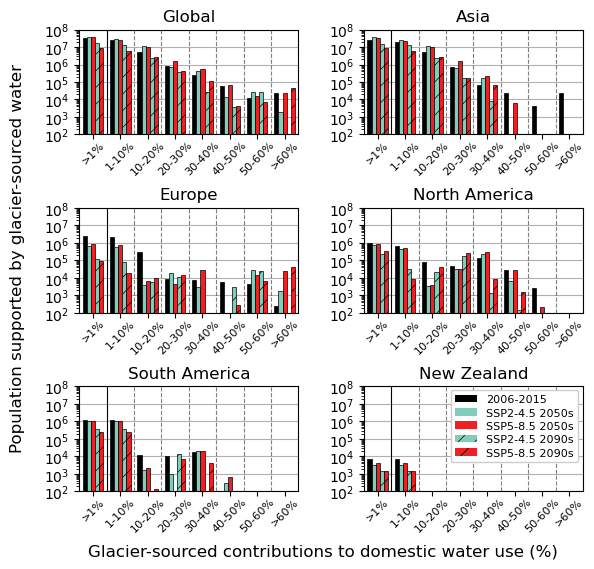

In [26]:
rois2plot = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']
# rois2plot = ['Global']

people_pg_fp = 'processed_data/domestic_pg_people/'

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6.5, 6), gridspec_kw={'hspace': 0.7, 'wspace':0.3})
axs = axs.flatten()  # make indexing easier

colors = [ssp_colordict[ssp] for ssp in ssps]
ssp_labels = [ssp_name_dict[ssp] for ssp in ssps]

for nroi, roi in enumerate(rois2plot):
    ax = axs[nroi]

    dfs = []
    
    # ----- Historical data -----
    people_pg_fn = 'historical_global_continents_people_pg_ERA5-byfrac-byelev.csv'
    people_pg_df = pd.read_csv(people_pg_fp + people_pg_fn)
    
    # decadal mean
    yr_cns = [str(x) for x in range(2006, 2016)]
    people_pg_df['2006-2015'] = people_pg_df.loc[:,yr_cns].mean(axis=1)

    # subset and take difference for bins
    people_pg_df_hist = people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                                         (people_pg_df['elev_threshold'] == 0), ['Name', 'frac', '2006-2015']]
    vals = people_pg_df_hist['2006-2015']
    bin_vals_df = pd.DataFrame({"bin": ['>1%', '1-10%', '10-20%', '20-30%', '30-40%', '40-50%', '50-60%', '>60%'],
                                "people": [vals.iloc[0]] + list(vals[:-1].values - vals[1:].values) + [vals.iloc[-1]]})
    dfs.append(bin_vals_df)
    
    # ----- Future data -----
    for yr_start in [2050, 2090]:
        
        for nssp, ssp in enumerate(['ssp245', 'ssp585']):
    
            people_pg_fn = ssp + '_global_continents_people_pg-byfrac-byelev_med.csv'
            people_pg_df = pd.read_csv(people_pg_fp + people_pg_fn)
            
            # decadal mean
            yr_cns = [str(x) for x in range(yr_start, yr_start+10)]
            decade_cn = yr_cns[0] + '-' + yr_cns[-1]
            people_pg_df[decade_cn] = people_pg_df.loc[:,yr_cns].mean(axis=1)
        
            # subset and take difference for bins
            people_pg_df_subset = people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                                                   (people_pg_df['elev_threshold'] == 0), ['Name', 'frac', decade_cn]]
            vals = people_pg_df_subset[decade_cn]
            bin_order = ['>1%', '1-10%', '10-20%', '20-30%', '30-40%', '40-50%', '50-60%', '>60%']
            bin_vals_df = pd.DataFrame({"bin": bin_order,
                                        "people": [vals.iloc[0]] + list(vals[:-1].values - vals[1:].values) + [vals.iloc[-1]]})
            dfs.append(bin_vals_df)

    # ----- PLOT THE DATA -----
    labels = ['2006-2015', 'SSP2-4.5 2050s', 'SSP5-8.5 2050s', 'SSP2-4.5 2090s', 'SSP5-8.5 2090s']
    
    # Combine
    plot_df = pd.concat([df.assign(dataset=label) for df, label in zip(dfs, labels)], ignore_index=True)
    
    # Pivot
    pivot = plot_df.pivot(index="bin", columns="dataset", values="people")
    pivot = pivot.loc[bin_order]
    pivot = pivot[labels]
    
    # Plot setup
    colors = ['k', ssp_colordict['ssp245'], ssp_colordict['ssp585'], ssp_colordict['ssp245'], ssp_colordict['ssp585']]
    hatches = ['', '', '', '//', '//']  # one pattern per dataset
    
    ax.set_axisbelow(True)
    mpl.rcParams['hatch.linewidth'] = 0.5

    # Plot data
    x = np.arange(pivot.shape[0])
    n = 5
    width = 0.15
    for i, col in enumerate(pivot.columns):
        offset = (i - n/2 + 0.5) * width
        ax.bar(x + offset, pivot[col], width, label=col, color=colors[i],
              edgecolor='k', linewidth=0.5, hatch=hatches[i])
    
    # ----- Vertical separators between bin groups -----
    # Solid line between >1% and 1-10%
    ax.axvline(x=0.5, color='k', linewidth=0.8, linestyle='-')
    
    # Dashed grey lines between all remaining groups
    for xpos in np.arange(1.5, len(bin_order) - 0.5, 1):
        ax.axvline(xpos, color='black', linewidth=0.8, alpha=0.5, linestyle='--')
    
    # ----- Axes formatting -----
    ax.set_ylim(1e2, 1e8)
    ax.set_yscale('log')

    ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))  # Major ticks
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=10))  # Minor ticks
    ax.yaxis.set_minor_formatter(NullFormatter())  # Hide minor tick labels
    ax.grid(axis='y', zorder=1)
    ax.margins(x=0)
    ax.set_xlim(-0.5, len(bin_order) - 0.5)
    
    ax.set_xticks(x)
    ax.set_xticklabels(pivot.index, rotation=45, ha='center', fontsize=9)
    ax.tick_params(axis='x', labelsize=8, pad=0)

    # Plot labels
    if roi in ['Australasia']:
        ax.set_title('New Zealand')
    elif roi in ['Central and South America']:
        ax.set_title('South America')
    else:
        ax.set_title(roi)

    if roi in ['Australasia']:
        legend_elements = []
        for i in range(len(dfs)):
            legend_elements.append(Patch(facecolor=colors[i], hatch=hatches[i], label=labels[i]))
        
        ax.legend(handles=legend_elements, fontsize=8, labelspacing=0.3,
                  loc="upper right", 
                  bbox_to_anchor=(0.98, 0.97), 
                  borderaxespad=0.03, frameon=True, facecolor='white', framealpha=1)

fig.supylabel('Population supported by glacier-sourced water', x=0.03, size=12, va='center', ha='center')
fig.supxlabel('Glacier-sourced contributions to domestic water use (%)', y=0.01, size=12, va='center', ha='center')
    
fig.savefig(paper_fig_fp + 'fig3_continent_people_binned_byperc.png', bbox_inches='tight', dpi=300)
plt.show()

# Population time series by region

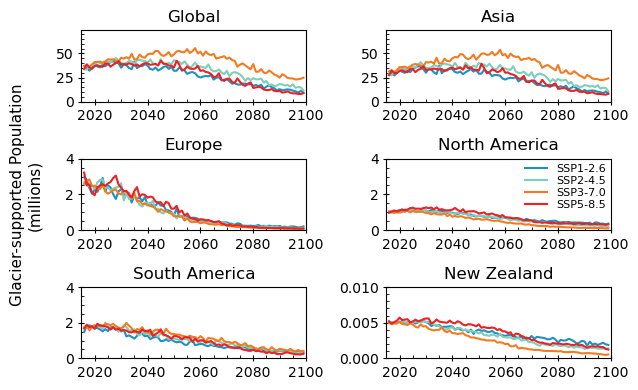

In [27]:
rois2plot = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']
# rois2plot = ['Global']

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6.5, 4))
axs = axs.flatten()  # make indexing easier

colors = [ssp_colordict[ssp] for ssp in ssps]
ssp_labels = [ssp_name_dict[ssp] for ssp in ssps]

for nroi, roi in enumerate(rois2plot):
    ax = axs[nroi]

    for nssp, ssp in enumerate(ssps):

        people_pg_fn = ssp + '_global_continents_people_pg-byfrac-byelev_med.csv'
        people_pg_df = pd.read_csv(people_pg_fp + people_pg_fn)

        years = np.arange(2016,2100)
        yr_cns = [str(x) for x in range(2016,2100)]
        data = people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                                (people_pg_df['elev_threshold'] == 0) & 
                                (people_pg_df['frac'] == 0.01), yr_cns].values[0,:]
            
        if roi in ['North America']:
            label = ssp_name_dict[ssp]
        else:
            label = None
        
        ax.plot(years, data/1e6, color=ssp_colordict[ssp], label=label)

    # Plot labels
    if roi in ['Australasia']:
        ax.set_title('New Zealand')
    elif roi in ['Central and South America']:
        ax.set_title('South America')
    else:
        ax.set_title(roi)
    
    ax.set_xlim(2015,2100)
    if roi in ['Global', 'Asia']:
        ax.set_ylim(0,74)
        ax.yaxis.set_major_locator(MultipleLocator(25)) 
        ax.yaxis.set_minor_locator(MultipleLocator(5))
    elif roi in ['Europe', 'North America', 'Central and South America']:
        ax.set_ylim(0,4)
        ax.yaxis.set_major_locator(MultipleLocator(2)) 
        ax.yaxis.set_minor_locator(MultipleLocator(0.5))
    else:
        ax.set_ylim(0,0.01)
        ax.yaxis.set_major_locator(MultipleLocator(0.005)) 
        ax.yaxis.set_minor_locator(MultipleLocator(0.001))

    if roi in ['North America']:
        ax.legend(fontsize=8, labelspacing=0.2, frameon=False, loc="upper right", 
                  bbox_to_anchor=(1, 1), borderaxespad=0.05)

    ax.xaxis.set_major_locator(MultipleLocator(20))
    ax.xaxis.set_minor_locator(MultipleLocator(5))
    ax.tick_params(axis='both', which='major', direction='inout', length=4)
    ax.tick_params(axis='both', which='minor', direction='in', length=2)

fig.supylabel('Glacier-supported Population\n(millions)', x=0.05, size=11, va='center', ha='center')
    
plt.tight_layout()
fig.savefig(paper_fig_fp + 'continent_people_timeseries.png', bbox_inches='tight', dpi=300)
plt.show()

# Population time series by region by percent

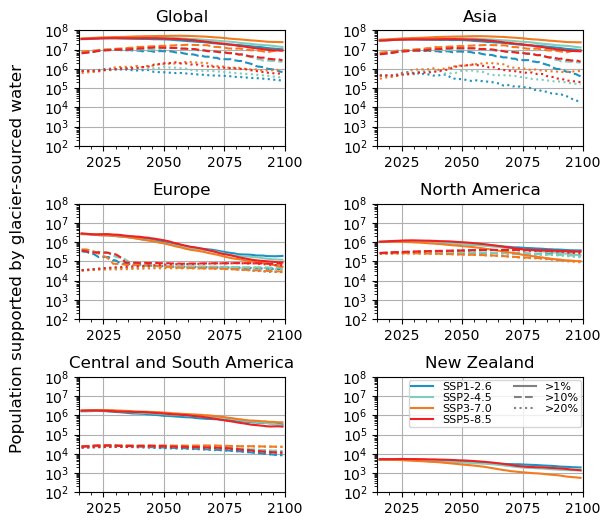

In [28]:
ssps2plot = ['ssp126', 'ssp245', 'ssp370', 'ssp585']

rois2plot = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']
# rois2plot = ['Global']

fracs2plot = [0.01, 0.1, 0.2]

fracs2plot_linestyles = ['-', '--', ':']


fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6.5, 6), gridspec_kw={'hspace': 0.5, 'wspace':0.45})
axs = axs.flatten()  # make indexing easier

for nroi, roi in enumerate(rois2plot):
    ax = axs[nroi]

    for ssp in ssps2plot:

        # Load data
        people_pg_fn = ssp + '_global_continents_people_pg-byfrac-byelev_med.csv'
        people_pg_df = pd.read_csv(people_pg_fp + people_pg_fn)

        years = np.arange(2016,2100)
        yr_cns = [str(x) for x in range(2016,2100)]

        # Plot the time series
        for nfrac, frac2plot in enumerate(fracs2plot):

            data = people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                                (people_pg_df['elev_threshold'] == 0) & 
                                (people_pg_df['frac'] == frac2plot), yr_cns].values[0,:]
            
            data_movingavg = uniform_filter(data, size=(11), mode='nearest')
            
            ax.plot(years, data_movingavg, linestyle=fracs2plot_linestyles[nfrac], color=ssp_colordict[ssp])

    
    # ----- LABELS/FORMATING -----
    ax.set_xlim(2015, 2100)
    ax.set_ylim(1e2,1e8)
    ax.set_yscale('log')
    ax.grid(True)

    ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))  # Major ticks
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=10))  # Minor ticks
    ax.yaxis.set_minor_formatter(NullFormatter())  # Hide minor tick labels
    ax.xaxis.set_major_locator(MultipleLocator(25))  # Major ticks every 25
    ax.xaxis.set_minor_locator(MultipleLocator(5))    # Minor ticks every 5

    if not roi in ['Australasia']:
        ax.set_title(roi)
    else:
        ax.set_title('New Zealand')

    if roi in ['Australasia']:
        legend_elements = []
        for ssp in ssps2plot:
            legend_elements.append(Line2D([0], [0], color=ssp_colordict[ssp], linestyle='-', label=ssp_name_dict[ssp]))
        for nfrac, frac2plot in enumerate(fracs2plot):
            legend_elements.append(Line2D([0], [0], color='grey', linestyle=fracs2plot_linestyles[nfrac], 
                                          label='>' + str(int(fracs2plot[nfrac]*100)) + '%'))
        ax.legend(handles=legend_elements, fontsize=8, labelspacing=0.1, ncol=2,
                  loc="upper right", bbox_to_anchor=(0.99, 0.97), borderaxespad=0.01, borderpad=0.15)

fig.supylabel('Population supported by glacier-sourced water', x=0.03, size=12, va='center', ha='center')
fig.savefig(paper_fig_fp + 'continent_people_timeseries_byperc.png', bbox_inches='tight', dpi=300)
plt.show()

# Population time series by region with high-mountain

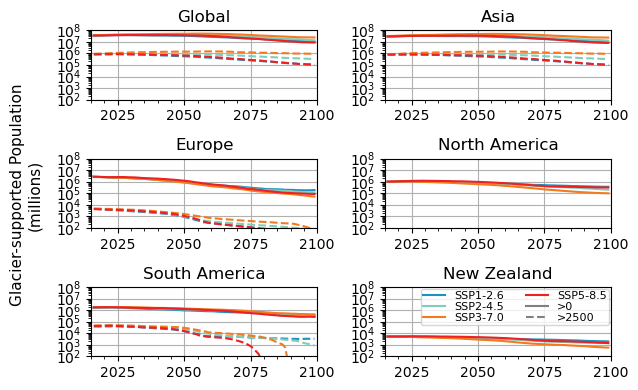

In [29]:
rois2plot = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']
# rois2plot = ['Global']

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6.5, 4))
axs = axs.flatten()  # make indexing easier

colors = [ssp_colordict[ssp] for ssp in ssps]
ssp_labels = [ssp_name_dict[ssp] for ssp in ssps]

elevs2plot = [0, 2500]
elevs2plot_linestyles = ['-', '--', ':']

for nroi, roi in enumerate(rois2plot):
    ax = axs[nroi]

    # ----- HISTORICAL -----
    people_pg_fn = 'historical_global_continents_people_pg_ERA5-byfrac-byelev.csv'
    people_pg_df = pd.read_csv(people_pg_fp + people_pg_fn)

    years_hist = range(1980,2016)
    yr_cns = [str(x) for x in years_hist]

    for nelev, elev2plot in enumerate(elevs2plot):
        
        data = people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                            (people_pg_df['elev_threshold'] == elev2plot) & 
                            (people_pg_df['frac'] == 0.01), yr_cns].values[0,:]
        data_movingavg = uniform_filter(data, size=(11), mode='nearest')
        ax.plot(years_hist, data_movingavg, linestyle=elevs2plot_linestyles[nelev], color='k')

    # ----- Future -----
    for nssp, ssp in enumerate(ssps):

        people_pg_fn = ssp + '_global_continents_people_pg-byfrac-byelev_med.csv'
        people_pg_df = pd.read_csv(people_pg_fp + people_pg_fn)

        years = range(2016,2100)
        yr_cns = [str(x) for x in years]
        
        for nelev, elev2plot in enumerate(elevs2plot):
            
            data = people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                                    (people_pg_df['elev_threshold'] == elev2plot) & 
                                    (people_pg_df['frac'] == 0.01), yr_cns].values[0,:]
            data_movingavg = uniform_filter(data, size=(11), mode='nearest')
            ax.plot(years, data_movingavg, linestyle=elevs2plot_linestyles[nelev], color=ssp_colordict[ssp])

    # Plot labels
    if roi in ['Australasia']:
        ax.set_title('New Zealand')
    elif roi in ['Central and South America']:
        ax.set_title('South America')
    else:
        ax.set_title(roi)
    
    ax.set_xlim(1980,2100)
    # if roi in ['Global', 'Asia']:
    #     ax.set_ylim(0,74)
    #     ax.yaxis.set_major_locator(MultipleLocator(25)) 
    #     ax.yaxis.set_minor_locator(MultipleLocator(5))
    # elif roi in ['Europe', 'North America', 'Central and South America']:
    #     ax.set_ylim(0,4)
    #     ax.yaxis.set_major_locator(MultipleLocator(2)) 
    #     ax.yaxis.set_minor_locator(MultipleLocator(0.5))
    # else:
    #     ax.set_ylim(0,0.01)
    #     ax.yaxis.set_major_locator(MultipleLocator(0.005)) 
    #     ax.yaxis.set_minor_locator(MultipleLocator(0.001))

    # if roi in ['North America']:
    #     ax.legend(fontsize=8, labelspacing=0.2, frameon=False, loc="upper right", 
    #               bbox_to_anchor=(1, 1), borderaxespad=0.05)

    ax.set_xlim(2015, 2100)
    ax.set_ylim(1e2,1e8)
    ax.set_yscale('log')
    ax.grid(True)

    ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))  # Major ticks
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=10))  # Minor ticks
    ax.yaxis.set_minor_formatter(NullFormatter())  # Hide minor tick labels
    ax.xaxis.set_major_locator(MultipleLocator(25))  # Major ticks every 25
    ax.xaxis.set_minor_locator(MultipleLocator(5))    # Minor ticks every 5

    if roi in ['Australasia']:
        legend_elements = []
        for ssp in ssps2plot:
            legend_elements.append(Line2D([0], [0], color=ssp_colordict[ssp], linestyle='-', label=ssp_name_dict[ssp]))
        for nelev, elev2plot in enumerate(elevs2plot):
            legend_elements.append(Line2D([0], [0], color='grey', linestyle=elevs2plot_linestyles[nelev], 
                                          label='>' + str(elevs2plot[nelev])))
        ax.legend(handles=legend_elements, fontsize=8, labelspacing=0.1, ncol=2,
                  loc="upper right", bbox_to_anchor=(0.99, 0.97), borderaxespad=0.01, borderpad=0.15)

fig.supylabel('Glacier-supported Population\n(millions)', x=0.05, size=11, va='center', ha='center')
    
plt.tight_layout()
fig.savefig(paper_fig_fp + 'continent_highmountain_population_timeseries.png', bbox_inches='tight', dpi=300)
plt.show()

# Population time series by region with high-mountain (Extended Figure 6)

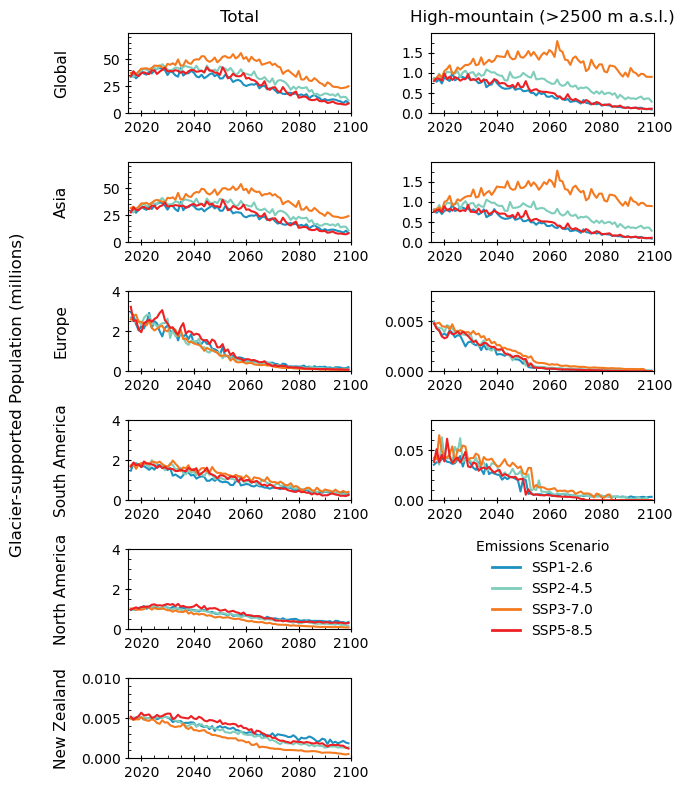

In [30]:
rois2plot = ['Global', 'Asia', 'Europe', 'Central and South America', 'North America', 'Australasia']
# rois2plot = ['Global']

elev = 2500
plot_hist = False

fig, axs = plt.subplots(nrows=6, ncols=2, figsize=(6.5, 8))

colors = [ssp_colordict[ssp] for ssp in ssps]
ssp_labels = [ssp_name_dict[ssp] for ssp in ssps]

for nroi, roi in enumerate(rois2plot):

    if plot_hist:
        # ----- Historical -----
        people_pg_fn = 'historical_global_continents_people_pg_ERA5-byfrac-byelev.csv'
        people_pg_df = pd.read_csv(people_pg_fp + people_pg_fn)
    
        years_hist = range(1980,2016)
        yrs_hist_cns = [str(x) for x in years_hist]
    
        # Total
        data_hist = people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                                     (people_pg_df['elev_threshold'] == 0) & 
                                     (people_pg_df['frac'] == 0.01), yrs_hist_cns].values[0,:]
        axs[nroi,0].plot(years_hist, data_hist/1e6, color='k')

        # High-mountain
        if roi not in ['North America', 'Australasia']: # no high-mountain population to include
            data_hist_high = people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                                              (people_pg_df['elev_threshold'] == elev) & 
                                              (people_pg_df['frac'] == 0.01), yrs_hist_cns].values[0,:]
            axs[nroi,1].plot(years_hist, data_hist_high/1e6, color='k')

    
    # ----- FUTURE -----
    for nssp, ssp in enumerate(ssps):

        people_pg_fn = ssp + '_global_continents_people_pg-byfrac-byelev_med.csv'
        people_pg_df = pd.read_csv(people_pg_fp + people_pg_fn)

        years = np.arange(2016,2100)
        yr_cns = [str(x) for x in range(2016,2100)]

        # Total
        data = people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                                (people_pg_df['elev_threshold'] == 0) & 
                                (people_pg_df['frac'] == 0.01), yr_cns].values[0,:]
        axs[nroi,0].plot(years, data/1e6, color=ssp_colordict[ssp], label=label)

        # High-mountain
        if roi not in ['North America', 'Australasia']: # no high-mountain population to include
            data_high = people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                                         (people_pg_df['elev_threshold'] == elev) & 
                                         (people_pg_df['frac'] == 0.01), yr_cns].values[0,:]
            axs[nroi,1].plot(years, data_high/1e6, color=ssp_colordict[ssp], label=label)
    

    # ----- Labels -----
    for ncol in [0,1]:
        # if ncol in [1] and roi in ['North America', 'Australasia']:
        #     axs[nroi,ncol].set_title(' ')
        # elif roi in ['Australasia']:
        #     axs[nroi,ncol].set_title('New Zealand')
        # elif roi in ['Central and South America']:
        #     axs[nroi,ncol].set_title('South America')
        # else:
        #     axs[nroi,ncol].set_title(roi)

        if plot_hist:
            axs[nroi,ncol].set_xlim(1980,2100)
            axs[nroi,ncol].xaxis.set_major_locator(MultipleLocator(40))
            axs[nroi,ncol].xaxis.set_minor_locator(MultipleLocator(10))
        else:
            axs[nroi,ncol].set_xlim(2015,2100)
            axs[nroi,ncol].xaxis.set_major_locator(MultipleLocator(20))
            axs[nroi,ncol].xaxis.set_minor_locator(MultipleLocator(5))
        
        axs[nroi,ncol].tick_params(axis='both', which='major', direction='inout', length=4)
        axs[nroi,ncol].tick_params(axis='both', which='minor', direction='in', length=2)

    # Total Population y-scale
    if roi in ['Global', 'Asia']:
        axs[nroi,0].set_ylim(0,74)
        axs[nroi,0].yaxis.set_major_locator(MultipleLocator(25)) 
        axs[nroi,0].yaxis.set_minor_locator(MultipleLocator(5))
    elif roi in ['Europe', 'North America', 'Central and South America']:
        axs[nroi,0].set_ylim(0,4)
        axs[nroi,0].yaxis.set_major_locator(MultipleLocator(2)) 
        axs[nroi,0].yaxis.set_minor_locator(MultipleLocator(0.5))
    else:
        axs[nroi,0].set_ylim(0,0.01)
        axs[nroi,0].yaxis.set_major_locator(MultipleLocator(0.005)) 
        axs[nroi,0].yaxis.set_minor_locator(MultipleLocator(0.001))

    # High-mountain Population y-scale
    if roi in ['Global', 'Asia']:
        axs[nroi,1].set_ylim(0,1.99)
        axs[nroi,1].yaxis.set_major_locator(MultipleLocator(0.5)) 
        axs[nroi,1].yaxis.set_minor_locator(MultipleLocator(0.25))
    elif roi in ['Europe']:
        axs[nroi,1].set_ylim(0,0.008)
        axs[nroi,1].yaxis.set_major_locator(MultipleLocator(0.005)) 
        axs[nroi,1].yaxis.set_minor_locator(MultipleLocator(0.001))
    elif roi in ['Central and South America']:
        axs[nroi,1].set_ylim(0,0.08)
        axs[nroi,1].yaxis.set_major_locator(MultipleLocator(0.05)) 
        axs[nroi,1].yaxis.set_minor_locator(MultipleLocator(0.01))

# Remove high-mountain North American & New Zealand axes
axs[4,1].axis('off')
axs[5,1].axis('off')

# Add legend
legend_handles = [Line2D([0], [0], color=ssp_colordict[ssp], lw=2, label=ssp_name_dict[ssp]) for ssp in ssps]

axs[4,1].legend(handles=legend_handles, loc='center', frameon=False, fontsize=10,
                title='Emissions Scenario', title_fontsize=10)

# Add labels on top
axs[0,0].set_title('Total', fontsize=12, pad=8)
axs[0,1].set_title('High-mountain (>2500 m a.s.l.)', fontsize=12, pad=8)

# Row labels on left side
for nroi, roi in enumerate(rois2plot):

    if roi == 'Australasia':
        label = 'New Zealand'
    elif roi == 'Central and South America':
        label = 'South America'
    else:
        label = roi

    axs[nroi,0].text(-0.3, 0.5, label, rotation=90, transform=axs[nroi,0].transAxes, va='center', ha='center', fontsize=11)

# fig.supylabel('Glacier-supported Population (millions)', x=-0.05, size=12, va='center', ha='center')
fig.text(-0.03, 0.5,'Glacier-supported Population (millions)',rotation=90,va='center',ha='center',fontsize=12)

plt.tight_layout()
fig.savefig(paper_fig_fp + 'continent_people_timeseries_whighmountain-futureonly.png', bbox_inches='tight', dpi=300)
plt.show()

### Include historical

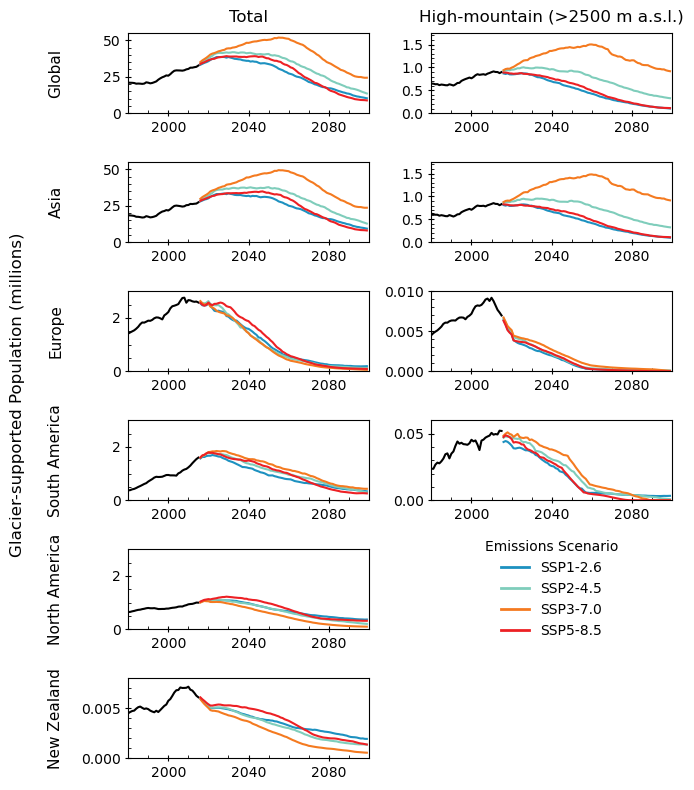

In [31]:
rois2plot = ['Global', 'Asia', 'Europe', 'Central and South America', 'North America', 'Australasia']
# rois2plot = ['Global']

elev = 2500
plot_hist = False

fig, axs = plt.subplots(nrows=6, ncols=2, figsize=(6.5, 8))

colors = [ssp_colordict[ssp] for ssp in ssps]
ssp_labels = [ssp_name_dict[ssp] for ssp in ssps]

for nroi, roi in enumerate(rois2plot):

    # ----- Historical -----
    people_pg_fn = 'historical_global_continents_people_pg_ERA5-byfrac-byelev.csv'
    people_pg_df = pd.read_csv(people_pg_fp + people_pg_fn)

    years_hist = range(1980,2016)
    yrs_hist_cns = [str(x) for x in years_hist]

    # Total
    data_hist = people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                                 (people_pg_df['elev_threshold'] == 0) & 
                                 (people_pg_df['frac'] == 0.01), yrs_hist_cns].values[0,:]
    data_hist_high = people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                                              (people_pg_df['elev_threshold'] == elev) & 
                                              (people_pg_df['frac'] == 0.01), yrs_hist_cns].values[0,:]
    # ----- Future -----
    for nssp, ssp in enumerate(ssps):

        people_pg_fn = ssp + '_global_continents_people_pg-byfrac-byelev_med.csv'
        people_pg_df = pd.read_csv(people_pg_fp + people_pg_fn)

        years = np.arange(2016,2100)
        yr_cns = [str(x) for x in range(2016,2100)]

        # Total
        data = people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                                (people_pg_df['elev_threshold'] == 0) & 
                                (people_pg_df['frac'] == 0.01), yr_cns].values[0,:]
        data_high = people_pg_df.loc[(people_pg_df['Name'] == roi) & 
                                     (people_pg_df['elev_threshold'] == elev) & 
                                     (people_pg_df['frac'] == 0.01), yr_cns].values[0,:]

        # ----- Contenate & plot ----- 
        data_hist_wssp = np.concatenate((data_hist, data)) / 1e6
        data_hist_wssp_movingavg = uniform_filter(data_hist_wssp, size=(11), mode='nearest')

        data_hist_wssp_high = np.concatenate((data_hist_high, data_high)) / 1e6
        data_hist_wssp_high_movingavg = uniform_filter(data_hist_wssp_high, size=(11), mode='nearest')
    
        if ssp in ['ssp245']:
            axs[nroi,0].plot(years_hist, data_hist_wssp_movingavg[0:data_hist.shape[0]], color='k')
            # High-mountain
            if roi not in ['North America', 'Australasia']: # no high-mountain population to include
                axs[nroi,1].plot(years_hist, data_hist_wssp_high_movingavg[0:data_hist.shape[0]], color='k')
            
        axs[nroi,0].plot(years, data_hist_wssp_movingavg[data_hist.shape[0]:], color=ssp_colordict[ssp])
        # High-mountain
        if roi not in ['North America', 'Australasia']: # no high-mountain population to include
            axs[nroi,1].plot(years, data_hist_wssp_high_movingavg[data_hist.shape[0]:], color=ssp_colordict[ssp])

    # ----- Labels -----
    for ncol in [0,1]:
        # if ncol in [1] and roi in ['North America', 'Australasia']:
        #     axs[nroi,ncol].set_title(' ')
        # elif roi in ['Australasia']:
        #     axs[nroi,ncol].set_title('New Zealand')
        # elif roi in ['Central and South America']:
        #     axs[nroi,ncol].set_title('South America')
        # else:
        #     axs[nroi,ncol].set_title(roi)

        axs[nroi,ncol].set_xlim(1980,2100)
        axs[nroi,ncol].xaxis.set_major_locator(MultipleLocator(40))
        axs[nroi,ncol].xaxis.set_minor_locator(MultipleLocator(10))
        
        axs[nroi,ncol].tick_params(axis='both', which='major', direction='inout', length=4)
        axs[nroi,ncol].tick_params(axis='both', which='minor', direction='in', length=2)

    # Total Population y-scale
    if roi in ['Global', 'Asia']:
        axs[nroi,0].set_ylim(0,55)
        axs[nroi,0].yaxis.set_major_locator(MultipleLocator(25)) 
        axs[nroi,0].yaxis.set_minor_locator(MultipleLocator(5))
    elif roi in ['Europe', 'North America', 'Central and South America']:
        axs[nroi,0].set_ylim(0,3)
        axs[nroi,0].yaxis.set_major_locator(MultipleLocator(2)) 
        axs[nroi,0].yaxis.set_minor_locator(MultipleLocator(0.5))
    else:
        axs[nroi,0].set_ylim(0,0.008)
        axs[nroi,0].yaxis.set_major_locator(MultipleLocator(0.005)) 
        axs[nroi,0].yaxis.set_minor_locator(MultipleLocator(0.001))

    # High-mountain Population y-scale
    if roi in ['Global', 'Asia']:
        axs[nroi,1].set_ylim(0,1.75)
        axs[nroi,1].yaxis.set_major_locator(MultipleLocator(0.5)) 
        axs[nroi,1].yaxis.set_minor_locator(MultipleLocator(0.1))
    elif roi in ['Europe']:
        axs[nroi,1].set_ylim(0,0.01)
        axs[nroi,1].yaxis.set_major_locator(MultipleLocator(0.005)) 
        axs[nroi,1].yaxis.set_minor_locator(MultipleLocator(0.001))
    elif roi in ['Central and South America']:
        axs[nroi,1].set_ylim(0,0.06)
        axs[nroi,1].yaxis.set_major_locator(MultipleLocator(0.05)) 
        axs[nroi,1].yaxis.set_minor_locator(MultipleLocator(0.01))

# Remove high-mountain North American & New Zealand axes
axs[4,1].axis('off')
axs[5,1].axis('off')

# Add legend
legend_handles = [Line2D([0], [0], color=ssp_colordict[ssp], lw=2, label=ssp_name_dict[ssp]) for ssp in ssps]

axs[4,1].legend(handles=legend_handles, loc='center', frameon=False, fontsize=10,
                title='Emissions Scenario', title_fontsize=10)

# Add labels on top
axs[0,0].set_title('Total', fontsize=12, pad=8)
axs[0,1].set_title('High-mountain (>2500 m a.s.l.)', fontsize=12, pad=8)

# Row labels on left side
for nroi, roi in enumerate(rois2plot):

    if roi == 'Australasia':
        label = 'New Zealand'
    elif roi == 'Central and South America':
        label = 'South America'
    else:
        label = roi

    axs[nroi,0].text(-0.3, 0.5, label, rotation=90, transform=axs[nroi,0].transAxes, va='center', ha='center', fontsize=11)

# fig.supylabel('Glacier-supported Population (millions)', x=-0.05, size=12, va='center', ha='center')
fig.text(-0.03, 0.5,'Glacier-supported Population (millions)',rotation=90,va='center',ha='center',fontsize=12)

plt.tight_layout()
fig.savefig(paper_fig_fp + 'figS6_continent_people_timeseries_whighmountain.png', bbox_inches='tight', dpi=300)
plt.show()